# EDA de viabilidad — Hito 2

Producto en **castellano**, evaluado **por módulo**: transcripción, separación de hablantes, minuta y de punta a punta.
Corre sobre `hito-2/muestra/`, sin red:

```
.venv/bin/jupyter nbconvert --to notebook --execute --inplace hito-2/notebooks/eda_viabilidad.ipynb
```

Cada celda de resultado empieza con su identificador (`[V1]`, `[K3]`, `[L2]`…).
Los niveles se leen de [`niveles-a-priori.md`](../niveles-a-priori.md).

In [1]:
# [SETUP] Rutas, niveles y registro de resultados
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def raiz_hito() -> Path:
    aqui = Path.cwd().resolve()
    for c in [aqui, *aqui.parents]:
        for cand in (c, c / "hito-2"):
            if (cand / "muestra" / "MANIFIESTO.json").exists():
                return cand
    raise FileNotFoundError("No encuentro hito-2/muestra/. Corré scripts/armar_muestra.py")

HITO = raiz_hito()
M = HITO / "muestra"
FIG = HITO / "figuras"
FIG.mkdir(exist_ok=True)

def leer_niveles(ruta: Path) -> pd.DataFrame:
    filas = [[c.strip() for c in l.strip().strip("|").split("|")]
             for l in ruta.read_text(encoding="utf8").splitlines() if l.startswith("| ")]
    return pd.DataFrame(filas[1:], columns=filas[0]).set_index("Id")

NIVELES = leer_niveles(HITO / "niveles-a-priori.md")
RESULTADOS, FUGAS = [], []

def registrar(id_, resultado, cumple, tipo="medido", nota=""):
    """Anota un nivel. cumple: 'sí', 'no', 'parcial' o 'sin decidir'."""
    n = NIVELES.loc[id_]
    fila = {"id": id_, "modulo": n["Módulo"], "propiedad": n["Propiedad"], "nivel": n["Nivel"],
            "tipo": tipo, "resultado": resultado, "cumple": cumple, "nota": nota}
    RESULTADOS.append(fila)
    print(f"[{id_}] {fila['modulo']} · {fila['propiedad']}\n   nivel:     {fila['nivel']}\n   resultado: {resultado}  ({tipo})"
          f"\n   cumple:    {cumple}" + (f"\n   nota:      {nota}" if nota else ""))

def registrar_fuga(id_, busqueda, resultado):
    FUGAS.append({"id": id_, "busqueda": busqueda, "resultado": resultado})
    print(f"[{id_}] {busqueda}\n   {resultado}")

def pct(x) -> str:
    return f"{100 * x:.1f}%"

def n_palabras(texto) -> int:
    return len(re.findall(r"[^\W\d_]+", texto or ""))

H = lambda segundos: segundos / 3600
print("muestra:", M.relative_to(HITO.parent), "| generada:", json.loads((M / "MANIFIESTO.json").read_text())["generado"])
NIVELES

muestra: hito-2/muestra | generada: 2026-10-12


,Módulo,Propiedad,Nivel,De dónde sale
Id,,,,
V1,Transcripción,Volumen,≥ 3 h y ≥ 30 hablantes en castellano rioplatense,"Medir el error por palabra con ±1 punto, sin depender de pocas voces"
V2,Transcripción,Volumen · habla espontánea,≥ 1 h (~9.000 palabras),"El producto transcribe reuniones, no lectura"
C1,Transcripción,Completitud,Transcripción en ≥ 99% de los audios,Sin referencia no se mide el error
C5,Transcripción,Completitud · datos demográficos,"Género, edad y acento en ≥ 70% de los clips de una fuente",Medir calidad de servicio por grupo
K1,Transcripción,Corrección · duplicados,≤ 1%,Inflan el volumen y contaminan la partición
K3,Transcripción,Corrección · audio,≥ 99% legible y con la duración declarada,Un audio roto es un caso perdido
K4,Transcripción,Corrección · texto,"≤ 1% con caracteres ajenos al castellano, después de normalizar por reglas",La métrica compara texto contra texto
G1,Transcripción,Vigencia,≥ 80% de las horas de 2015 en adelante,Vocabulario y grabación actuales
R1,Transcripción,Representatividad · género,Ningún género bajo el 30%,Usuarios ~50/50


In [2]:
# [CARGA] Tablas de la muestra
# Transcripción (castellano rioplatense)
slr_t = pd.read_csv(M / "slr61/transcripciones.csv")
slr_a = pd.read_csv(M / "slr61/manifiesto_audio.csv")
cor_g = pd.read_csv(M / "cordeba/grabaciones.csv")
cor_t = pd.read_parquet(M / "cordeba/turnos.parquet")
hum_g = pd.read_csv(M / "humyn/grabaciones.csv")
hum_t = pd.read_parquet(M / "humyn/turnos.parquet")
# Separación de hablantes
ami_r = pd.read_csv(M / "ami/reuniones.csv")
ami_p = pd.read_csv(M / "ami/participantes.csv")
ami_t = pd.read_parquet(M / "ami/turnos.parquet")
ami_x = pd.read_csv(M / "ami/extractos.csv")
icsi_r = pd.read_csv(M / "icsi/reuniones.csv")
icsi_h = pd.read_csv(M / "icsi/hablantes.csv")
icsi_t = pd.read_parquet(M / "icsi/turnos.parquet")
icsi_x = pd.read_csv(M / "icsi/extractos.csv")
ami_en = pd.read_parquet(M / "ami/extractos_energia.parquet")      # energía del audio de cada extracto, por cuadro de 20 ms
icsi_en = pd.read_parquet(M / "icsi/extractos_energia.parquet")
vox = pd.read_parquet(M / "voxconverse/rttm.parquet")
vox_a = pd.read_csv(M / "voxconverse/audio.csv")
# Minuta
ami_m = pd.read_parquet(M / "ami/minutas.parquet")
ami_e = pd.read_parquet(M / "ami/evidencias.parquet")

TABLAS = {"slr61/transcripciones": slr_t, "slr61/manifiesto_audio": slr_a, "cordeba/grabaciones": cor_g,
          "cordeba/turnos": cor_t, "humyn/grabaciones": hum_g, "humyn/turnos": hum_t,
          "ami/reuniones": ami_r, "ami/participantes": ami_p, "ami/turnos": ami_t, "ami/extractos": ami_x,
          "ami/extractos_energia": ami_en, "icsi/extractos_energia": icsi_en,
          "ami/minutas": ami_m, "ami/evidencias": ami_e,
          "icsi/reuniones": icsi_r, "icsi/hablantes": icsi_h, "icsi/turnos": icsi_t, "icsi/extractos": icsi_x,
          "voxconverse/rttm": vox, "voxconverse/audio": vox_a}

# La duración de cada reunión es la de su audio (los metadatos de AMI no son confiables).
ami_r["duracion_declarada_s"] = ami_r.duracion_s
ami_r["duracion_s"] = ami_r.audio_duracion_s
icsi_r["ultimo_turno_s"] = icsi_r.duracion_s
icsi_r["duracion_s"] = icsi_r.audio_duracion_s

# Tablas derivadas
for t in (ami_t, icsi_t):
    t["dur"] = (t.fin - t.inicio).clip(lower=0)
slr = slr_t.merge(slr_a, on="archivo", how="left")
hum_es = hum_g[hum_g.idioma.str.startswith("Spanish")]
hum_ar = hum_g[hum_g.idioma.str.contains("Argentina")]
hum_t_ar = hum_t[hum_t.idioma.str.contains("Argentina")]
cor = cor_g.assign(con_turnos=cor_g.n_turnos > 2, palabras_por_min=cor_g.n_palabras / (cor_g.duracion_s / 60))
vox_s = (vox.assign(fin=vox.inicio + vox.duracion).groupby(["particion", "sesion"])
         .agg(duracion_s=("fin", "max"), n_hablantes=("hablante", "nunique")).reset_index())
# Las minutas traen marcadores de "no hubo" ('*NA*', 'NA.') escritos como un ítem: no cuentan.
ami_m["marcador_vacio"] = ami_m.texto.str.strip().str.fullmatch(r"\*?N/?A\*?\.?", case=False)
ami_mi = ami_m[~ami_m.marcador_vacio]

pd.DataFrame([{"tabla": k, "filas": len(v), "columnas": ", ".join(v.columns)} for k, v in TABLAS.items()])

,tabla,filas,columnas
0,slr61/transcripciones,5739,"archivo, genero, hablante, texto, en_muestra_de_audio"
1,slr61/manifiesto_audio,5739,"archivo, bytes, legible, frecuencia_hz, canales, duracion_s, pico"
2,cordeba/grabaciones,24,"archivo, bytes, legible, duracion_s, codec, frecuencia_hz, canales, n_turnos, n_hablantes, n_palabras"
3,cordeba/turnos,5187,"archivo, orden, hablante, texto"
4,humyn/grabaciones,28,"archivo, idioma, tipo, legible, duracion_s, codec, frecuencia_hz, canales, transcripcion_con_turnos, trans..."
5,humyn/turnos,445,"archivo, idioma, orden, hablante, inicio, fin, texto"
6,ami/reuniones,171,"reunion, serie, tipo, fecha_cruda, anio, duracion_s, n_hablantes, hablantes, particion_oficial, particion_..."
7,ami/participantes,189,"hablante, sexo, edad, lengua_nativa"
8,ami/turnos,93637,"reunion, agente, hablante, inicio, fin, n_palabras, texto, dur"
9,ami/extractos,16,"reunion, archivo, inicio_s, duracion_s, frecuencia_hz, canales"


In [3]:
# [ESCUCHAR] Reproduce el extracto de 30 s de una reunión, por su identificador
from IPython.display import Audio, display

EXTRACTOS = pd.concat([ami_x.assign(corpus="ami"), icsi_x.assign(corpus="icsi")]).set_index("reunion")

def escuchar(reunion: str):
    """Muestra el reproductor del extracto y lo que dice la transcripción en esos 30 s."""
    if reunion not in EXTRACTOS.index:
        raise KeyError(f"'{reunion}' no tiene extracto. Opciones: {', '.join(EXTRACTOS.index)}")
    x = EXTRACTOS.loc[reunion]
    datos, hz = sf.read(M / x.corpus / x.archivo, dtype="float32", always_2d=True)
    turnos = ami_t if x.corpus == "ami" else icsi_t
    t = turnos[(turnos.reunion == reunion) & (turnos.fin > x.inicio_s) & (turnos.inicio < x.inicio_s + x.duracion_s)]
    print(f"{reunion} ({x.corpus.upper()}) · segundos {x.inicio_s}–{x.inicio_s + x.duracion_s} de la reunión")
    display(Audio(datos.mean(axis=1), rate=hz))
    return t[["hablante", "inicio", "fin", "texto"]].sort_values("inicio").reset_index(drop=True)

# Identificadores con extracto (descomentá uno para probarlo):
# AMI:  ES2005c ES2007c ES2012c ES2014d IS1002d IS1003a IS1004b IS1006a
#       TS3005c TS3008a TS3010a TS3012c EN2001b EN2009d IB4003 IB4004
# ICSI: Bmr006 Bmr026 Bmr030 Bro010 Bro018 Bro025 Bed006 Bed015
# escuchar("ES2005c")
# escuchar("EN2001b")
# escuchar("Bmr006")
# El audio no se versiona: se genera en muestra/*/extractos con scripts/armar_muestra.py
# escuchar("TS3008a")

## A. Transcripción (castellano rioplatense)

Fuentes: OpenSLR 61 (leído), CORdeBA (espontáneo, sin tiempos) y Humyn LATAM · Argentina (espontáneo, con tiempos).

In [4]:
# [V1] Volumen · horas y hablantes en castellano rioplatense
vol = pd.DataFrame([
    {"fuente": "OpenSLR 61", "estilo": "leído", "horas": H(slr.duracion_s.sum()), "palabras": int(slr_t.texto.map(n_palabras).sum()),
     "hablantes": f"{slr.hablante.nunique()} identificados"},
    {"fuente": "CORdeBA", "estilo": "espontáneo", "horas": H(cor_g.duracion_s.sum()), "palabras": int(cor_g.n_palabras.sum()),
     "hablantes": f"≤ {int(cor_g.n_hablantes.sum())} (etiquetas por grabación)"},
    {"fuente": "Humyn · Argentina", "estilo": "espontáneo", "horas": H(hum_ar.duracion_s.sum()), "palabras": int(hum_ar.n_palabras.sum()),
     "hablantes": f"≤ {int(hum_ar.n_hablantes.sum())}"},
])
display(vol.round(2))
h_es, n_hab = vol.horas.sum(), slr.hablante.nunique()
registrar("V1", f"{h_es:.1f} h y {n_hab} hablantes identificados (OpenSLR 61 {vol.horas[0]:.1f} h; CORdeBA "
                f"{vol.horas[1]:.1f} h; Humyn Argentina {vol.horas[2]:.2f} h)",
          "sí" if h_es >= 3 and n_hab >= 30 else "no")

,fuente,estilo,horas,palabras,hablantes
0,OpenSLR 61,leído,8.03,52275,44 identificados
1,CORdeBA,espontáneo,6.42,57016,≤ 68 (etiquetas por grabación)
2,Humyn · Argentina,espontáneo,0.52,3499,≤ 4


[V1] Transcripción · Volumen
   nivel:     ≥ 3 h y ≥ 30 hablantes en castellano rioplatense
   resultado: 15.0 h y 44 hablantes identificados (OpenSLR 61 8.0 h; CORdeBA 6.4 h; Humyn Argentina 0.52 h)  (medido)
   cumple:    sí


In [5]:
# [V2] Volumen · habla espontánea transcripta
pal_hum = int(hum_t_ar.texto.map(n_palabras).sum())
h_hum_texto = H(hum_t_ar.groupby("archivo").fin.max().sum())
pal_cor = int(cor[cor.legible].n_palabras.sum())
registrar("V2", f"{pal_hum + pal_cor} palabras ({pal_cor} de CORdeBA, sin tiempos; {pal_hum} de Humyn Argentina, "
                f"{h_hum_texto:.2f} h con tiempos)", "sí" if pal_hum + pal_cor >= 9000 else "no",
          nota="Con tiempos por turno solo hay Humyn Argentina")

[V2] Transcripción · Volumen · habla espontánea
   nivel:     ≥ 1 h (~9.000 palabras)
   resultado: 58076 palabras (54577 de CORdeBA, sin tiempos; 3499 de Humyn Argentina, 0.37 h con tiempos)  (medido)
   cumple:    sí
   nota:      Con tiempos por turno solo hay Humyn Argentina


,con_texto_s,idioma,duracion_s,cobertura
archivo,,,,
Spanish_Argentina_1.wav,630.00,Spanish- Argentina,937.81,0.67
Spanish_Argentina_2.wav,689.98,Spanish- Argentina,930.93,0.74
Spanish_Peru_1.wav,659.98,Spanish- Peru,916.99,0.72
Spanish_Peru_2.wav,630.00,Spanish- Peru,923.56,0.68
Spanish_Venezuela_1.wav,659.98,Spanish- Venezuela,940.76,0.70
Spanish_Venezuela_2.wav,689.98,Spanish- Venezuela,899.54,0.77


,archivo,legible,duracion_s,n_turnos,con_turnos,n_palabras,palabras_por_min
0,CordeBA_0001.mp3,True,913.8,195,True,2673,175.5
1,CordeBA_0002.mp3,True,748.7,116,True,1014,81.3
2,CordeBA_0003.mp3,True,407.0,111,True,1062,156.5
3,CordeBA_0004.mp3,True,901.2,183,True,2706,180.2
4,CordeBA_0005.mp3,True,1119.7,328,True,1972,105.7
5,CordeBA_0006.mp3,True,1418.2,570,True,3880,164.1
6,CordeBA_0007.mp3,True,840.9,193,True,2362,168.5
7,CordeBA_0008.mp3,True,890.0,286,True,1911,128.8
8,CordeBA_0009.mp3,True,1104.9,1,False,3067,166.5
9,CordeBA_0010.mp3,True,1046.4,313,True,2894,165.9


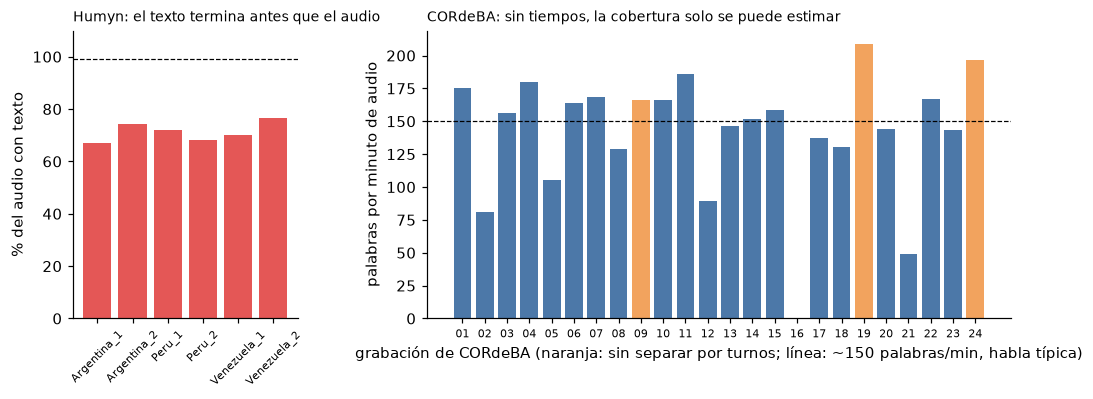

[C1] Transcripción · Completitud
   nivel:     Transcripción en ≥ 99% de los audios
   resultado: OpenSLR 61: 100.0%. Humyn: el texto cubre 71.4% del audio. CORdeBA: sin tiempos; 3 de 23 grabaciones bajo 100 palabras/min  (medido)
   cumple:    parcial
   nota:      Cumple OpenSLR 61. Humyn no. CORdeBA no se puede medir sin alinear


In [6]:
# [C1] Completitud · transcripción presente en los audios
audio_con_texto = slr_a.archivo.isin(slr_t.archivo).mean()
cob = (hum_t.groupby("archivo").fin.max().rename("con_texto_s").to_frame()
       .join(hum_g.set_index("archivo")[["idioma", "duracion_s"]]))
cob["cobertura"] = cob.con_texto_s / cob.duracion_s
display(cob.round(2))
display(cor[["archivo", "legible", "duracion_s", "n_turnos", "con_turnos", "n_palabras", "palabras_por_min"]].round(1))

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 2.6], "wspace": .32})
a.bar(cob.index.str.replace("Spanish_", "").str.replace(".wav", ""), cob.cobertura * 100, color="#e45756")
a.axhline(99, ls="--", c="k", lw=.8); a.set_ylim(0, 110); a.set_ylabel("% del audio con texto")
a.set_title("Humyn: el texto termina antes que el audio", fontsize=9, loc="left"); a.tick_params(axis="x", rotation=45, labelsize=7)
b.bar(cor.archivo.str.extract(r"(\d+)")[0].str[-2:], cor.palabras_por_min.fillna(0), color=np.where(cor.con_turnos, "#4c78a8", "#f2a35e"))
b.axhline(150, ls="--", c="k", lw=.8); b.set_ylabel("palabras por minuto de audio")
b.set_xlabel("grabación de CORdeBA (naranja: sin separar por turnos; línea: ~150 palabras/min, habla típica)")
b.set_title("CORdeBA: sin tiempos, la cobertura solo se puede estimar", fontsize=9, loc="left"); b.tick_params(axis="x", labelsize=7)
fig.savefig(FIG / "fig2_cobertura_transcripcion.png", dpi=150, bbox_inches="tight"); plt.show()

ppm = cor[cor.legible].palabras_por_min
registrar("C1", f"OpenSLR 61: {pct(audio_con_texto)}. Humyn: el texto cubre {pct(cob.cobertura.mean())} del audio. "
                f"CORdeBA: sin tiempos; {int((ppm < 100).sum())} de {len(ppm)} grabaciones bajo 100 palabras/min",
          "parcial", nota="Cumple OpenSLR 61. Humyn no. CORdeBA no se puede medir sin alinear")

In [7]:
# [C5] Completitud · género, edad y acento por clip
c5 = pd.DataFrame([
    {"fuente": "OpenSLR 61", "género": "100%", "edad": "0%", "acento": "único (Buenos Aires)"},
    {"fuente": "CORdeBA", "género": "0%", "edad": "0%", "acento": "único (Prov. de Buenos Aires)"},
    {"fuente": "Humyn · Argentina", "género": "0%", "edad": "0%", "acento": "solo país"},
])
display(c5)
registrar("C5", "Ninguna fuente trae los tres datos: OpenSLR 61 solo género; CORdeBA y Humyn, ninguno", "no",
          nota="Common Voice 26 rioplatense los declara en su ficha; pide cuenta para descargar")

,fuente,género,edad,acento
0,OpenSLR 61,100%,0%,único (Buenos Aires)
1,CORdeBA,0%,0%,único (Prov. de Buenos Aires)
2,Humyn · Argentina,0%,0%,solo país


[C5] Transcripción · Completitud · datos demográficos
   nivel:     Género, edad y acento en ≥ 70% de los clips de una fuente
   resultado: Ninguna fuente trae los tres datos: OpenSLR 61 solo género; CORdeBA y Humyn, ninguno  (medido)
   cumple:    no
   nota:      Common Voice 26 rioplatense los declara en su ficha; pide cuenta para descargar


In [8]:
# [K1] Corrección · duplicados exactos
k1 = pd.DataFrame([
    ("slr61 · mismo archivo", len(slr_t), slr_t.archivo.duplicated().sum()),
    ("slr61 · mismo hablante y texto", len(slr_t), slr_t.duplicated(["hablante", "texto"]).sum()),
    ("cordeba · mismo tamaño de archivo", len(cor_g), cor_g.bytes.duplicated().sum()),
    ("humyn en castellano · misma transcripción", len(hum_es), hum_es.transcripcion_sha1.duplicated().sum()),
], columns=["comprobación", "filas", "duplicados"])
k1["pct"] = (k1.duplicados / k1.filas).map(pct)
display(k1)
peor = k1.loc[(k1.duplicados / k1.filas).idxmax()]
registrar("K1", f"Máximo {pct(peor.duplicados / peor.filas)}: {int(peor.duplicados)} de {int(peor.filas)} clips de "
                f"OpenSLR 61 repiten hablante y oración", "sí" if peor.duplicados / peor.filas <= .01 else "no",
          nota="Se deja un clip de cada par")

,comprobación,filas,duplicados,pct
0,slr61 · mismo archivo,5739,0,0.0%
1,slr61 · mismo hablante y texto,5739,78,1.4%
2,cordeba · mismo tamaño de archivo,24,0,0.0%
3,humyn en castellano · misma transcripción,6,0,0.0%


[K1] Transcripción · Corrección · duplicados
   nivel:     ≤ 1%
   resultado: Máximo 1.4%: 78 de 5739 clips de OpenSLR 61 repiten hablante y oración  (medido)
   cumple:    no
   nota:      Se deja un clip de cada par


In [9]:
# [K3] Corrección · audio legible y con la duración declarada
k3 = pd.DataFrame([
    ("OpenSLR 61 · todo el audio, decodificado al armar la muestra", len(slr_a), slr_a.legible.mean()),
    ("CORdeBA", len(cor_g), cor_g.legible.mean()),
    ("Humyn LATAM", len(hum_g), hum_g.legible.mean()),
], columns=["comprobación", "archivos", "legibles"])
display(k3.assign(legibles=k3.legibles.map(pct)))
print("OpenSLR 61 · duración (s):", slr_a.duracion_s.describe()[["min", "50%", "max"]].round(2).to_dict(),
      "| formato:", slr_a.groupby(["frecuencia_hz", "canales"]).size().to_dict(), "| saturados:", int((slr_a.pico >= .999).sum()))
print("CORdeBA · ilegible:", cor_g[~cor_g.legible][["archivo", "bytes"]].to_dict("records"))
registrar("K3", f"OpenSLR 61: {pct(slr_a.legible.mean())} de {len(slr_a)}. CORdeBA: {int(cor_g.legible.sum())} de {len(cor_g)}. "
                f"Humyn: {pct(hum_g.legible.mean())}",
          "parcial", nota="No cumple CORdeBA: " + ", ".join(cor_g[~cor_g.legible].archivo) + " no es audio")

,comprobación,archivos,legibles
0,"OpenSLR 61 · todo el audio, decodificado al armar la muestra",5739,100.0%
1,CORdeBA,24,95.8%
2,Humyn LATAM,28,100.0%


OpenSLR 61 · duración (s): {'min': 1.88, '50%': 4.86, 'max': 11.95} | formato: {(48000, 1): 5739} | saturados: 3
CORdeBA · ilegible: [{'archivo': 'CordeBA_0016.wma', 'bytes': 21194}]
[K3] Transcripción · Corrección · audio
   nivel:     ≥ 99% legible y con la duración declarada
   resultado: OpenSLR 61: 100.0% de 5739. CORdeBA: 23 de 24. Humyn: 100.0%  (medido)
   cumple:    parcial
   nota:      No cumple CORdeBA: CordeBA_0016.wma no es audio


In [10]:
# [K4] Corrección · texto con caracteres ajenos al castellano, después de normalizar por reglas
PERMITIDOS = set("abcdefghijklmnopqrstuvwxyzáéíóúüñ0123456789 .,;:¿?¡!\"'()-…—–%")
TIPOGRAFICAS = str.maketrans({"‘": "'", "’": "'", "´": "'", "“": '"', "”": '"', "«": '"', "»": '"'})

def normalizar(t: str) -> str:
    t = re.sub(r"[\[\]=<>*/]", " ", (t or "").lower().translate(TIPOGRAFICAS))   # marcas de oralidad
    return re.sub(r"\s+", " ", t).strip()

k4 = pd.DataFrame([{"fuente": f, "unidades": len(s), "con_ajenos": s.map(lambda t: bool(set(normalizar(t)) - PERMITIDOS)).mean()}
                   for f, s in [("OpenSLR 61", slr_t.texto), ("Humyn castellano", hum_t.texto), ("CORdeBA", cor_t.texto)]])
display(k4.assign(con_ajenos=k4.con_ajenos.map(pct)))
solape = cor_t.texto.map(lambda t: bool(re.search(r"[\[\]=]", t or ""))).mean()
registrar("K4", "; ".join(f"{f}: {pct(v)}" for f, v in zip(k4.fuente, k4.con_ajenos)),
          "sí" if k4.con_ajenos.max() <= .01 else "no",
          nota=f"CORdeBA: {pct(solape)} de los turnos trae marcas de solapamiento, que la regla quita")

,fuente,unidades,con_ajenos
0,OpenSLR 61,5739,0.0%
1,Humyn castellano,445,0.4%
2,CORdeBA,5187,0.0%


[K4] Transcripción · Corrección · texto
   nivel:     ≤ 1% con caracteres ajenos al castellano, después de normalizar por reglas
   resultado: OpenSLR 61: 0.0%; Humyn castellano: 0.4%; CORdeBA: 0.0%  (medido)
   cumple:    sí
   nota:      CORdeBA: 26.3% de los turnos trae marcas de solapamiento, que la regla quita


In [11]:
# [G1] Vigencia · horas grabadas de 2015 en adelante
h_slr, h_cor, h_hum = H(slr.duracion_s.sum()), H(cor_g.duracion_s.sum()), H(hum_ar.duracion_s.sum())
display(pd.DataFrame([("OpenSLR 61", "2018–2019", "ficha y artículo de 2020"), ("CORdeBA", "2014–2019", "ficha; sin fecha por grabación"),
                      ("Humyn LATAM", "No sabemos", "publicado en 2026")], columns=["fuente", "período", "procedencia"]))
peor = h_slr / (h_slr + h_cor + h_hum)
esperado = (h_slr + h_cor * 5 / 6 + h_hum) / (h_slr + h_cor + h_hum)
registrar("G1", f"Entre {pct(peor)} (peor caso) y {pct(esperado)} (CORdeBA repartido parejo en 2014–2019)",
          "sin decidir", tipo="estimado", nota="Procedencia: fichas de las fuentes")

,fuente,período,procedencia
0,OpenSLR 61,2018–2019,ficha y artículo de 2020
1,CORdeBA,2014–2019,ficha; sin fecha por grabación
2,Humyn LATAM,No sabemos,publicado en 2026


[G1] Transcripción · Vigencia
   nivel:     ≥ 80% de las horas de 2015 en adelante
   resultado: Entre 53.6% (peor caso) y 92.8% (CORdeBA repartido parejo en 2014–2019)  (estimado)
   cumple:    sin decidir
   nota:      Procedencia: fichas de las fuentes


In [12]:
# [R1] Representatividad · género
g = slr.groupby("genero").agg(horas=("duracion_s", lambda s: H(s.sum())), hablantes=("hablante", "nunique"))
g["pct_horas"] = g.horas / g.horas.sum()
display(g.assign(pct_horas=g.pct_horas.map(pct)).round(2))
registrar("R1", f"OpenSLR 61: {pct(g.pct_horas['female'])} de las horas son de mujeres y {pct(g.pct_horas['male'])} de "
                f"varones ({int(g.hablantes['female'])} y {int(g.hablantes['male'])} hablantes)",
          "sí" if g.pct_horas.min() >= .30 else "no", nota="Única fuente en castellano con género")

,horas,hablantes,pct_horas
genero,,,
female,5.61,31,69.9%
male,2.42,13,30.1%


[R1] Transcripción · Representatividad · género
   nivel:     Ningún género bajo el 30%
   resultado: OpenSLR 61: 69.9% de las horas son de mujeres y 30.1% de varones (31 y 13 hablantes)  (medido)
   cumple:    sí
   nota:      Única fuente en castellano con género


In [13]:
# [R2] Representatividad · edad (30 años o más)
registrar("R2", "Ninguna fuente en castellano trae edad por hablante. CORdeBA declara mediana de 24 años", "no",
          tipo="estimado", nota="Procedencia: ficha de CORdeBA")

[R2] Transcripción · Representatividad · edad
   nivel:     ≥ 50% de hablantes de 30 años o más
   resultado: Ninguna fuente en castellano trae edad por hablante. CORdeBA declara mediana de 24 años  (estimado)
   cumple:    no
   nota:      Procedencia: ficha de CORdeBA


In [14]:
# [R3] Representatividad · habla espontánea sobre el total de horas
r3 = (h_cor + h_hum) / (h_cor + h_hum + h_slr)
registrar("R3", f"{pct(r3)} de las horas son espontáneas ({h_cor + h_hum:.1f} h de {h_cor + h_hum + h_slr:.1f} h)",
          "sí" if r3 >= .5 else "no", nota="Casi todo lo espontáneo es CORdeBA: sin tiempos y de uso no comercial")

[R3] Transcripción · Representatividad · estilo
   nivel:     ≥ 50% de las horas de habla espontánea
   resultado: 46.4% de las horas son espontáneas (6.9 h de 15.0 h)  (medido)
   cumple:    no
   nota:      Casi todo lo espontáneo es CORdeBA: sin tiempos y de uso no comercial


In [15]:
# [F1] Confiabilidad · transcripción hecha o validada por personas
display(pd.DataFrame([
    ("OpenSLR 61", "Voluntarios leen oraciones; control manual", "ficha"),
    ("CORdeBA", "Transcripto y revisado por docentes de la UNLP", "ficha"),
    ("Humyn LATAM", "Transcripción manual revisada", "ficha del proveedor"),
], columns=["fuente", "qué declara", "procedencia"]))
raras = hum_g[~hum_g.transcripcion_con_turnos]
registrar("F1", f"Las tres fuentes declaran transcripción humana. Medido: {len(raras)} de {len(hum_g)} filas de Humyn no "
                f"traen la transcripción con turnos que promete su ficha ({raras.transcripcion_sha1.nunique()} textos distintos)",
          "parcial", tipo="estimado", nota="Las 6 grabaciones de Humyn en castellano no tienen esa anomalía")

,fuente,qué declara,procedencia
0,OpenSLR 61,Voluntarios leen oraciones; control manual,ficha
1,CORdeBA,Transcripto y revisado por docentes de la UNLP,ficha
2,Humyn LATAM,Transcripción manual revisada,ficha del proveedor


[F1] Transcripción · Confiabilidad
   nivel:     100% transcripto o validado por personas
   resultado: Las tres fuentes declaran transcripción humana. Medido: 20 de 28 filas de Humyn no traen la transcripción con turnos que promete su ficha (8 textos distintos)  (estimado)
   cumple:    parcial
   nota:      Las 6 grabaciones de Humyn en castellano no tienen esa anomalía


In [16]:
# [F3] Confiabilidad · error de la referencia
n_clips = int(slr_t.en_muestra_de_audio.sum())
registrar("F3", f"Pendiente: doble transcripción de {n_clips} clips (uno por hablante)", "sin decidir", tipo="no medido")

[F3] Transcripción · Confiabilidad · error de la referencia
   nivel:     ≤ 2% de desacuerdo entre dos transcriptores del equipo
   resultado: Pendiente: doble transcripción de 44 clips (uno por hablante)  (no medido)
   cumple:    sin decidir


## B. Separación de hablantes

No depende del idioma. Fuentes: AMI, ICSI y VoxConverse (inglés), y Humyn LATAM en castellano.

,fuente,idioma,sesiones,horas,audio_disponible
0,AMI,inglés,171,100.0,171 de 171 (11.5 GB)
1,ICSI,inglés,75,71.7,75 de 75 (8.3 GB)
2,VoxConverse,inglés (mayoría),448,63.5,sí (6.3 GB)
3,Humyn · castellano,castellano,6,1.1,sí


[V3] Separación de hablantes · Volumen
   nivel:     ≥ 20 sesiones y ≥ 3 h con turnos con tiempos
   resultado: 700 sesiones y 236 h (AMI 171, ICSI 75, VoxConverse 448, Humyn castellano 6)  (medido)
   cumple:    sí
   nota:      En castellano: 6 sesiones (1.1 h), todas de 2 hablantes


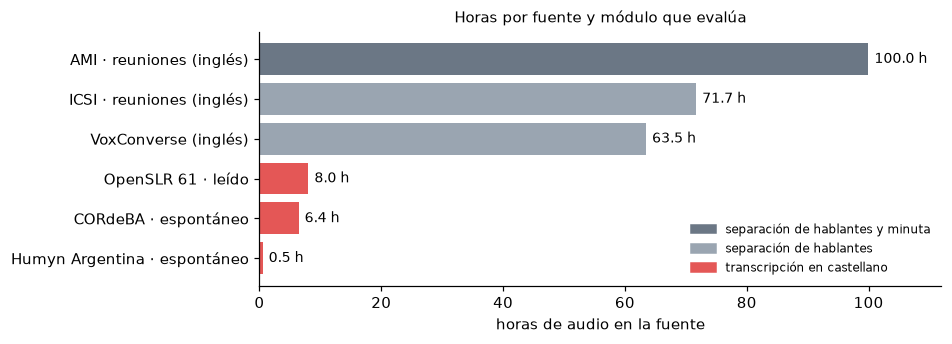

In [17]:
# [V3] Volumen · sesiones con turnos con tiempos
diar = pd.DataFrame([
    {"fuente": "AMI", "idioma": "inglés", "sesiones": len(ami_r), "horas": H(ami_r.duracion_s.sum()),
     "audio_disponible": f"{int(ami_r.audio_disponible.sum())} de {len(ami_r)} ({ami_r.audio_bytes.sum() / 1e9:.1f} GB)"},
    {"fuente": "ICSI", "idioma": "inglés", "sesiones": len(icsi_r), "horas": H(icsi_r.duracion_s.sum()),
     "audio_disponible": f"{int(icsi_r.audio_disponible.sum())} de {len(icsi_r)} ({icsi_r.audio_bytes.sum() / 1e9:.1f} GB)"},
    {"fuente": "VoxConverse", "idioma": "inglés (mayoría)", "sesiones": len(vox_s), "horas": H(vox_s.duracion_s.sum()),
     "audio_disponible": f"sí ({vox_a.audio_bytes.sum() / 1e9:.1f} GB)"},
    {"fuente": "Humyn · castellano", "idioma": "castellano", "sesiones": len(hum_es),
     "horas": H(hum_t.groupby("archivo").fin.max().sum()), "audio_disponible": "sí"},
])
display(diar.round(1))
registrar("V3", f"{int(diar.sesiones.sum())} sesiones y {diar.horas.sum():.0f} h (AMI {len(ami_r)}, ICSI {len(icsi_r)}, "
                f"VoxConverse {len(vox_s)}, Humyn castellano {len(hum_es)})",
          "sí" if diar.sesiones.sum() >= 20 and diar.horas.sum() >= 3 else "no",
          nota=f"En castellano: {len(hum_es)} sesiones ({diar.horas[3]:.1f} h), todas de 2 hablantes")

partes = pd.DataFrame([
    ("AMI · reuniones (inglés)", H(ami_r.duracion_s.sum()), "separación de hablantes y minuta"),
    ("ICSI · reuniones (inglés)", H(icsi_r.duracion_s.sum()), "separación de hablantes"),
    ("VoxConverse (inglés)", H(vox_s.duracion_s.sum()), "separación de hablantes"),
    ("OpenSLR 61 · leído", h_slr, "transcripción en castellano"),
    ("CORdeBA · espontáneo", h_cor, "transcripción en castellano"),
    ("Humyn Argentina · espontáneo", h_hum, "transcripción en castellano"),
], columns=["fuente", "horas", "módulo"]).iloc[::-1]
color = {"separación de hablantes y minuta": "#6b7785", "separación de hablantes": "#9aa5b1", "transcripción en castellano": "#e45756"}
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(partes.fuente, partes.horas, color=partes["módulo"].map(color))
for y, v in enumerate(partes.horas):
    ax.text(v + 1, y, f"{v:.1f} h", va="center", fontsize=9)
ax.set_xlabel("horas de audio en la fuente"); ax.set_xlim(0, partes.horas.max() * 1.12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in color.values()], labels=list(color), frameon=False, fontsize=8)
ax.set_title("Horas por fuente y módulo que evalúa", fontsize=10)
fig.savefig(FIG / "fig1_horas_por_fuente.png", dpi=150, bbox_inches="tight"); plt.show()

In [18]:
# [C2] Completitud · hablante presente en cada turno
c2 = pd.DataFrame([(f, len(t), t.hablante.notna().mean()) for f, t in
                   [("AMI", ami_t), ("ICSI", icsi_t), ("VoxConverse", vox), ("Humyn castellano", hum_t)]],
                  columns=["fuente", "turnos", "con_hablante"])
display(c2.assign(con_hablante=c2.con_hablante.map(pct)))
registrar("C2", f"{pct(c2.con_hablante.min())} de los turnos con hablante en las cuatro fuentes",
          "sí" if c2.con_hablante.min() >= .95 else "no")

,fuente,turnos,con_hablante
0,AMI,93637,100.0%
1,ICSI,129106,100.0%
2,VoxConverse,27747,100.0%
3,Humyn castellano,445,100.0%


[C2] Separación de hablantes · Completitud
   nivel:     Hablante en ≥ 95% de los turnos
   resultado: 100.0% de los turnos con hablante en las cuatro fuentes  (medido)
   cumple:    sí


,fuente,turnos,fin_menor_o_igual_que_inicio
0,AMI,93637,2
1,ICSI,129106,0
2,VoxConverse,27747,0
3,Humyn castellano,445,10


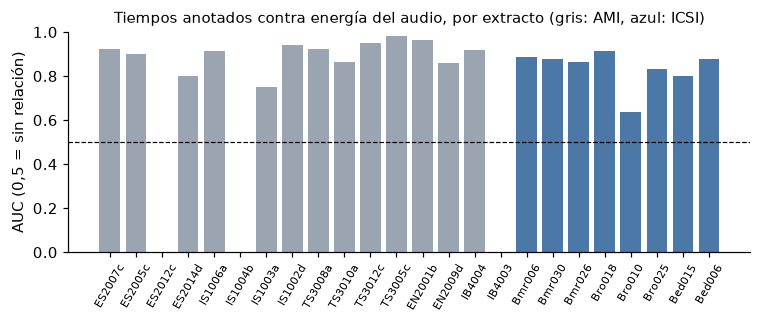

[K2] Separación de hablantes · Corrección · tiempos
   nivel:     0 turnos con fin ≤ inicio
   resultado: 12 turnos con fin ≤ inicio: AMI 2, ICSI 0, VoxConverse 0, Humyn castellano 10  (medido)
   cumple:    no
   nota:      Se descartan por regla. En 21 extractos de AMI e ICSI los tiempos coinciden con el audio (AUC mediana 0.89, mínima 0.64)


In [19]:
# [K2] Corrección · turnos con tiempos imposibles, y cotejo de los tiempos contra el audio
k2 = pd.DataFrame([
    ("AMI", len(ami_t), int((ami_t.fin <= ami_t.inicio).sum())), ("ICSI", len(icsi_t), int((icsi_t.fin <= icsi_t.inicio).sum())),
    ("VoxConverse", len(vox), int((vox.duracion <= 0).sum())), ("Humyn castellano", len(hum_t), int((hum_t.fin <= hum_t.inicio).sum())),
], columns=["fuente", "turnos", "fin_menor_o_igual_que_inicio"])
display(k2)

def cotejo(corpus, tabla, energia, turnos, paso=0.02):
    """Por extracto: AUC de la energía del audio como predictor del habla anotada (0,5 = sin relación)."""
    filas = []
    for _, x in tabla.iterrows():
        e = energia[energia.reunion == x.reunion].sort_values("cuadro").energia.to_numpy()
        centro = x.inicio_s + (np.arange(len(e)) + .5) * paso
        t = turnos[(turnos.reunion == x.reunion) & (turnos.n_palabras > 0)]
        habla = np.zeros(len(e), bool)
        for ini, fin in zip(t.inicio, t.fin):
            habla |= (centro >= ini) & (centro < fin)
        auc = np.nan
        if habla.any() and not habla.all():
            r = pd.Series(e).rank().to_numpy()
            auc = (r[habla].sum() - habla.sum() * (habla.sum() + 1) / 2) / (habla.sum() * (~habla).sum())
        filas.append({"corpus": corpus, "reunion": x.reunion, "auc": auc})
    return pd.DataFrame(filas)

cj = pd.concat([cotejo("ami", ami_x, ami_en, ami_t), cotejo("icsi", icsi_x, icsi_en, icsi_t)], ignore_index=True)
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.bar(cj.reunion, cj.auc.fillna(0), color=np.where(cj.corpus == "ami", "#9aa5b1", "#4c78a8"))
ax.axhline(.5, ls="--", c="k", lw=.8); ax.set_ylim(0, 1); ax.set_ylabel("AUC (0,5 = sin relación)")
ax.tick_params(axis="x", rotation=60, labelsize=7)
ax.set_title("Tiempos anotados contra energía del audio, por extracto (gris: AMI, azul: ICSI)", fontsize=10)
fig.savefig(FIG / "fig4_tiempos_contra_audio.png", dpi=150, bbox_inches="tight"); plt.show()
auc = cj.auc.dropna()
total = int(k2.fin_menor_o_igual_que_inicio.sum())
registrar("K2", f"{total} turnos con fin ≤ inicio: " + ", ".join(f"{f} {n}" for f, n in zip(k2.fuente, k2.fin_menor_o_igual_que_inicio)),
          "sí" if total == 0 else "no",
          nota=f"Se descartan por regla. En {len(auc)} extractos de AMI e ICSI los tiempos coinciden con el audio "
               f"(AUC mediana {auc.median():.2f}, mínima {auc.min():.2f})")

In [20]:
# [G2] Vigencia · al menos una fuente con audio de videollamada
display(pd.DataFrame([("AMI", "sala instrumentada, 2004–2005"), ("ICSI", "sala de reuniones, 2001–2002"),
                      ("VoxConverse", "videos de YouTube"), ("Humyn LATAM", "No sabemos")], columns=["fuente", "modalidad"]))
registrar("G2", "0 de 4 fuentes declaran audio de videollamada", "no", tipo="estimado",
          nota="Procedencia: documentación de las fuentes")

,fuente,modalidad
0,AMI,"sala instrumentada, 2004–2005"
1,ICSI,"sala de reuniones, 2001–2002"
2,VoxConverse,videos de YouTube
3,Humyn LATAM,No sabemos


[G2] Separación de hablantes · Vigencia · modalidad
   nivel:     Al menos una fuente de videollamada
   resultado: 0 de 4 fuentes declaran audio de videollamada  (estimado)
   cumple:    no
   nota:      Procedencia: documentación de las fuentes


,fuente,sesiones,de_3_a_8,mediana,habla_superpuesta
0,AMI,171,100.0%,4.0,17.4%
1,ICSI,75,89.3%,6.0,10.6%
2,VoxConverse,448,56.9%,5.0,3.3%
3,Humyn castellano,6,0.0%,2.0,0.0%


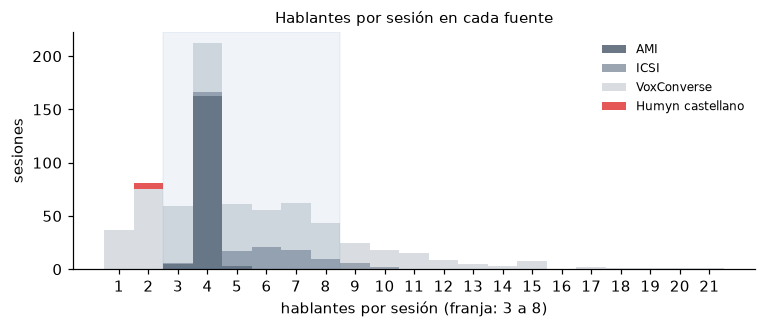

[R4] Separación de hablantes · Representatividad · tamaño
   nivel:     ≥ 50% de las sesiones con 3 a 8 hablantes
   resultado: 70.4% de las 700 sesiones (AMI 100.0%, ICSI 89.3%, VoxConverse 56.9%, Humyn 0.0%)  (medido)
   cumple:    sí
   nota:      Habla superpuesta: 17.4% en AMI, 10.6% en ICSI, 3.3% en VoxConverse


In [21]:
# [R4] Representatividad · tamaño de la reunión (3 a 8 hablantes) y habla superpuesta
tam = {"AMI": ami_r.n_hablantes, "ICSI": icsi_r.n_hablantes, "VoxConverse": vox_s.n_hablantes, "Humyn castellano": hum_es.n_hablantes}
r4 = pd.DataFrame([{"fuente": k, "sesiones": len(v), "de_3_a_8": v.between(3, 8).mean(), "mediana": v.median()} for k, v in tam.items()])

def superpuesta(t, ini="inicio", fin="fin", grupo="reunion"):
    """Fracción del tiempo con habla en la que hablan dos o más personas a la vez."""
    uno = dos = 0.0
    for _, g in t.dropna(subset=[ini, fin]).groupby(grupo):
        ev = np.concatenate([np.c_[g[ini].to_numpy(), np.ones(len(g))], np.c_[g[fin].to_numpy(), -np.ones(len(g))]])
        ev = ev[np.lexsort((ev[:, 1], ev[:, 0]))]
        activos, tramo = np.cumsum(ev[:, 1])[:-1], np.diff(ev[:, 0])
        uno += tramo[activos >= 1].sum(); dos += tramo[activos >= 2].sum()
    return dos / uno

r4["habla_superpuesta"] = [superpuesta(ami_t[ami_t.n_palabras > 0]), superpuesta(icsi_t[icsi_t.n_palabras > 0]),
                           superpuesta(vox.assign(fin=vox.inicio + vox.duracion), grupo="sesion"), superpuesta(hum_t, grupo="archivo")]
display(r4.assign(de_3_a_8=r4.de_3_a_8.map(pct), habla_superpuesta=r4.habla_superpuesta.map(pct)))
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist([v.clip(upper=21) for v in tam.values()], bins=np.arange(.5, 22.5, 1), stacked=True, label=list(tam),
        color=["#6b7785", "#9aa5b1", "#d9dde2", "#e45756"])
ax.axvspan(2.5, 8.5, color="#4c78a8", alpha=.08); ax.set_xlabel("hablantes por sesión (franja: 3 a 8)")
ax.set_ylabel("sesiones"); ax.legend(frameon=False, fontsize=8); ax.set_xticks(range(1, 22))
ax.set_title("Hablantes por sesión en cada fuente", fontsize=10)
fig.savefig(FIG / "fig3_hablantes_por_sesion.png", dpi=150, bbox_inches="tight"); plt.show()
todas = pd.concat(tam.values())
registrar("R4", f"{pct(todas.between(3, 8).mean())} de las {len(todas)} sesiones (AMI {pct(r4.de_3_a_8[0])}, ICSI "
                f"{pct(r4.de_3_a_8[1])}, VoxConverse {pct(r4.de_3_a_8[2])}, Humyn {pct(r4.de_3_a_8[3])})",
          "sí" if todas.between(3, 8).mean() >= .5 else "no",
          nota=f"Habla superpuesta: {pct(r4.habla_superpuesta[0])} en AMI, {pct(r4.habla_superpuesta[1])} en ICSI, "
               f"{pct(r4.habla_superpuesta[2])} en VoxConverse")

In [22]:
# [R6] Representatividad · horas de reuniones reales (no actuadas)
h_act = H(ami_r[ami_r.tipo == "scenario"].duracion_s.sum())
h_real_ami = H(ami_r[ami_r.tipo == "nonscenario"].duracion_s.sum())
h_icsi = H(icsi_r.duracion_s.sum())
r6 = (h_real_ami + h_icsi) / (h_act + h_real_ami + h_icsi)
registrar("R6", f"{pct(r6)} de las horas de reunión son reales ({h_icsi:.1f} h de ICSI y {h_real_ami:.1f} h de AMI; "
                f"{h_act:.1f} h actuadas)", "sí" if r6 >= .30 else "no")

[R6] Separación de hablantes · Representatividad · reuniones reales
   nivel:     ≥ 30% de las horas de reuniones no actuadas
   resultado: 57.8% de las horas de reunión son reales (71.7 h de ICSI y 27.5 h de AMI; 72.5 h actuadas)  (medido)
   cumple:    sí


## C. Minuta

AMI: única fuente con resumen, decisiones y acciones escritos por personas, y con cada ítem enlazado a la transcripción. Está en inglés.

In [23]:
# [M1] Volumen · minuta de referencia de AMI (resumen, decisiones y acciones)
por_tipo = ami_mi.groupby("tipo").agg(items=("item_id", "size"), reuniones=("reunion", "nunique"))
por_tipo["items_por_reunion"] = (por_tipo["items"] / por_tipo["reuniones"]).round(1)
display(por_tipo)
print("Marcadores vacíos ('*NA*') excluidos:", ami_m[ami_m.marcador_vacio].tipo.value_counts().to_dict())

conteo_m = ami_mi.groupby(["reunion", "tipo"]).size().unstack(fill_value=0)
completas_m = conteo_m[(conteo_m.resumen > 0) & (conteo_m.decision > 0) & (conteo_m.accion > 0)]
por_grupo = (ami_r.assign(grupo=ami_r.reunion.str[:2])
             .groupby("grupo").agg(reuniones=("reunion", "size"), con_minuta=("tiene_minuta", "sum"),
                                   horas=("duracion_s", lambda s: H(s.sum()))).round(1))
display(por_grupo)

series_m = ami_r[ami_r.reunion.isin(completas_m.index)].serie.nunique()
registrar("M1", f"{len(completas_m)} reuniones con resumen, decisiones y acciones, en {series_m} series "
                f"({int(ami_r.tiene_minuta.sum())} de {len(ami_r)} tienen alguna minuta; {len(ami_mi)} ítems)",
          "sí" if len(completas_m) >= 10 else "no",
          nota=f"Sin contar {int(ami_m.marcador_vacio.sum())} marcadores '*NA*'. {int((conteo_m.accion == 0).sum())} "
               f"reuniones sin acciones y {int((conteo_m.decision == 0).sum())} sin decisiones. Las EN e IN no tienen minuta")

,items,reuniones,items_por_reunion
tipo,,,
accion,284,111,2.6
decision,688,134,5.1
problema,431,122,3.5
resumen,1199,142,8.4


Marcadores vacíos ('*NA*') excluidos: {'accion': 22, 'problema': 19, 'decision': 6}


,reuniones,con_minuta,horas
grupo,,,
EN,16,0,15.0
ES,60,60,30.4
IB,7,4,4.3
IN,10,0,8.2
IS,38,38,17.8
TS,40,40,24.3


[M1] Minuta · Volumen
   nivel:     ≥ 10 reuniones con resumen, decisiones y acciones de referencia
   resultado: 105 reuniones con resumen, decisiones y acciones, en 37 series (142 de 171 tienen alguna minuta; 2602 ítems)  (medido)
   cumple:    sí
   nota:      Sin contar 47 marcadores '*NA*'. 31 reuniones sin acciones y 8 sin decisiones. Las EN e IN no tienen minuta


In [24]:
# [M2] Representatividad · horas de reuniones con minuta que no son actuadas
con_m = ami_r[ami_r.tiene_minuta]
h_con_m = H(con_m.duracion_s.sum())
h_real_m = H(con_m[con_m.tipo == "nonscenario"].duracion_s.sum())
m2 = h_real_m / h_con_m
display(con_m.assign(tipo=con_m.tipo.map({"scenario": "actuadas", "nonscenario": "reales"}))
        .groupby("tipo").agg(reuniones=("reunion", "size"), horas=("duracion_s", lambda s: H(s.sum()))).round(1))
grupos_reales = ", ".join(sorted(con_m[con_m.tipo == "nonscenario"].reunion.str[:2].unique())) or "ninguno"
registrar("M2", f"{pct(m2)} de las horas con minuta son de reuniones no actuadas ({h_real_m:.1f} h de {h_con_m:.1f} h)",
          "sí" if m2 >= .30 else "no",
          nota=f"Grupos de reuniones reales con minuta: {grupos_reales}. El resto es el escenario del control remoto")

,reuniones,horas
tipo,,
actuadas,138,72.5
reales,4,2.6


[M2] Minuta · Representatividad · reuniones reales
   nivel:     ≥ 30% de las horas con minuta son de reuniones no actuadas
   resultado: 3.5% de las horas con minuta son de reuniones no actuadas (2.6 h de 75.1 h)  (medido)
   cumple:    no
   nota:      Grupos de reuniones reales con minuta: IB. El resto es el escenario del control remoto


In [25]:
# [M3] Confiabilidad · el juez (LLM) coincide con la anotación humana
registrar("M3", "Pendiente: el equipo etiqueta a mano una muestra de ítems de minuta y se compara contra el juez",
          "sin decidir", tipo="no medido")

[M3] Minuta · Confiabilidad · juez
   nivel:     El juez (LLM) coincide con la anotación humana en ≥ 80% de los ítems (κ de Cohen ≥ 0,6)
   resultado: Pendiente: el equipo etiqueta a mano una muestra de ítems de minuta y se compara contra el juez  (no medido)
   cumple:    sin decidir


In [26]:
# [C4] Completitud · decisiones y acciones enlazadas a un fragmento de la transcripción
it = ami_mi[ami_mi.tipo.isin(["decision", "accion"])].merge(ami_r[["reunion", "tiene_evidencias"]], on="reunion")
c4 = (it.n_evidencias > 0).mean()
display((ami_mi.n_evidencias > 0).groupby(ami_mi.tipo).mean().map(pct).rename("ítems con evidencia").to_frame()
        .assign(fragmentos_por_item=ami_mi.groupby("tipo").n_evidencias.median()))
ej = it[it.n_evidencias.between(1, 3)].iloc[0]
print("Ejemplo ·", ej.reunion, "·", ej.tipo, "·", ej.texto)
display(ami_e[ami_e.item_id == ej.item_id][["hablante", "inicio", "fin", "texto"]])
registrar("C4", f"{pct(c4)} de las {len(it)} decisiones y acciones tienen al menos un fragmento enlazado "
                f"({len(ami_e)} enlaces en {int(ami_r.tiene_evidencias.sum())} reuniones)", "sí" if c4 >= .80 else "no",
          nota=f"{int((~it.tiene_evidencias).sum())} ítems están en reuniones sin archivo de enlaces")

,ítems con evidencia,fragmentos_por_item
tipo,,
accion,90.1%,1.0
decision,90.7%,2.0
problema,91.9%,4.0
resumen,95.7%,10.0


Ejemplo · ES2002a · accion · The industrial designer will work on the working design of the remote.


,hablante,inicio,fin,texto
49,FEE005,985.49,994.81,"Um so inbetween now and then, um as the industrial designer, you're gonna be working on you know the actua..."


[C4] Minuta · Completitud · evidencia
   nivel:     ≥ 80% de las decisiones y acciones enlazadas a un fragmento de la transcripción
   resultado: 90.5% de las 972 decisiones y acciones tienen al menos un fragmento enlazado (22100 enlaces en 137 reuniones)  (medido)
   cumple:    sí
   nota:      43 ítems están en reuniones sin archivo de enlaces


In [27]:
# [R5] Representatividad · minutas de referencia en castellano
ES = {"el", "la", "los", "las", "de", "que", "y", "en", "se", "un", "una", "para", "con", "por", "del"}
EN = {"the", "of", "and", "to", "will", "was", "is", "in", "that", "for", "be", "they", "their", "on"}

def idioma(texto: str) -> str:
    w = re.findall(r"[a-záéíóúñ]+", texto.lower())
    return "castellano" if sum(x in ES for x in w) > sum(x in EN for x in w) else "inglés"

idiomas = ami_mi.groupby("reunion").texto.agg(" ".join).map(idioma)
n_es = int((idiomas == "castellano").sum())
registrar("R5", f"{n_es} de {len(idiomas)} reuniones con minuta la tienen en castellano", "sí" if n_es >= 30 else "no",
          nota="Se cubre con un dataset derivado: transcripción y minuta de AMI traducidas automáticamente")

[R5] Minuta · Representatividad · idioma
   nivel:     ≥ 30 reuniones con minuta de referencia en castellano
   resultado: 0 de 142 reuniones con minuta la tienen en castellano  (medido)
   cumple:    no
   nota:      Se cubre con un dataset derivado: transcripción y minuta de AMI traducidas automáticamente


## D. De punta a punta

In [28]:
# [V5] Volumen · reuniones en castellano con audio, transcripción, hablantes y minuta
cap = pd.DataFrame([
    ("OpenSLR 61", True, False, False, False), ("CORdeBA", True, True, False, False), ("Humyn · Argentina", True, True, True, False),
    ("AMI", False, True, True, True), ("ICSI", False, True, True, False), ("VoxConverse", False, False, True, False),
], columns=["fuente", "castellano", "transcripción_de_conversación", "hablantes_con_tiempos", "minuta"])
display(cap)
n = int((cap.castellano & cap["transcripción_de_conversación"] & cap.hablantes_con_tiempos & cap.minuta).sum())
registrar("V5", f"{n} fuentes (0 reuniones) reúnen castellano, transcripción, hablantes con tiempos y minuta",
          "sí" if n else "no", nota="Requiere reuniones propias")

,fuente,castellano,transcripción_de_conversación,hablantes_con_tiempos,minuta
0,OpenSLR 61,True,False,False,False
1,CORdeBA,True,True,False,False
2,Humyn · Argentina,True,True,True,False
3,AMI,False,True,True,True
4,ICSI,False,True,True,False
5,VoxConverse,False,False,True,False


[V5] De punta a punta · Volumen
   nivel:     ≥ 10 reuniones en castellano de ≥ 20 min con audio, transcripción, hablantes y minuta
   resultado: 0 fuentes (0 reuniones) reúnen castellano, transcripción, hablantes con tiempos y minuta  (medido)
   cumple:    no
   nota:      Requiere reuniones propias


## E. Exposición al *leakage*

No se entrena ningún modelo. Se busca lo que inflaría la evaluación: datos que el modelo ya vio, personas o textos repetidos entre particiones e información que el producto no tiene al predecir.

In [29]:
# [L1] La definición · columnas que se completan después del momento de predecir
ROL = {"texto": "referencia", "n_palabras": "referencia", "hablante": "referencia", "agente": "referencia",
       "inicio": "referencia", "fin": "referencia", "duracion": "referencia", "dur": "referencia",
       "lectura_de_digitos": "referencia", "n_hablantes": "referencia", "hablantes": "referencia",
       "palabras": "referencia", "palabras_sin_tiempo": "referencia", "duracion_s": "referencia",
       "n_turnos": "referencia", "tipo": "referencia", "orden": "referencia", "item_id": "referencia",
       "acto_id": "referencia", "n_evidencias": "referencia", "marcador_vacio": "referencia",
       "audio_url": "entrada", "archivo": "entrada", "energia": "entrada"}
cols = pd.DataFrame([{"tabla": t, "columna": c, "rol": ROL.get(c, "metadato")} for t, d in TABLAS.items() for c in d.columns])
n_ref, n_ent = int((cols.rol == "referencia").sum()), int((cols.rol == "entrada").sum())
registrar_fuga("L1", "La definición",
               f"{n_ref} de {len(cols)} columnas son anotación posterior; {n_ent} apuntan al audio, lo único que recibe el "
               f"producto. No se le pasa al sistema la cantidad de hablantes ni los tiempos de habla. La minuta se evalúa "
               f"sobre la salida del transcriptor, no sobre la transcripción manual")

[L1] La definición
   65 de 151 columnas son anotación posterior; 13 apuntan al audio, lo único que recibe el producto. No se le pasa al sistema la cantidad de hablantes ni los tiempos de habla. La minuta se evalúa sobre la salida del transcriptor, no sobre la transcripción manual


In [30]:
# [L2] El tiempo · ¿el modelo ya vio estos datos?
py = ami_r.particion_pyannote.fillna("").replace("", "no figura").value_counts()
anios_icsi = pd.to_datetime(icsi_h.fecha_formulario, errors="coerce").dt.year.dropna().astype(int)
entrenamiento, prueba = int(py.get("train", 0) + py.get("dev", 0)), int(py.get("test", 0))
registrar_fuga("L2", "El tiempo",
               f"pyannote declara AMI y VoxConverse como datos de entrenamiento: {entrenamiento} de {len(ami_r)} reuniones de "
               f"AMI están en su parte de entrenamiento o ajuste y {prueba} en la de prueba. ICSI no figura: quedan "
               f"{prueba + len(icsi_r)} reuniones no vistas. Las minutas de AMI ({ami_r.anio.min()}–{ami_r.anio.max()}) son "
               f"públicas hace más de 15 años: un modelo de lenguaje pudo haberlas visto. Whisper no publica sus datos")

[L2] El tiempo
   pyannote declara AMI y VoxConverse como datos de entrenamiento: 154 de 171 reuniones de AMI están en su parte de entrenamiento o ajuste y 16 en la de prueba. ICSI no figura: quedan 91 reuniones no vistas. Las minutas de AMI (2004–2005) son públicas hace más de 15 años: un modelo de lenguaje pudo haberlas visto. Whisper no publica sus datos


In [31]:
# [L3] Los duplicados · textos repetidos
oraciones = slr_t.groupby("texto").hablante.nunique()
repetidas = (slr_t.texto.map(oraciones) > 1).mean()

def fichas(t):
    return frozenset(re.findall(r"[a-z0-9]+", t.lower()))

it = ami_mi[ami_mi.tipo.isin(["decision", "accion"])].merge(ami_r[["reunion", "serie"]], on="reunion").reset_index(drop=True)
tok, serie = it.texto.map(fichas).tolist(), it.serie.tolist()
casi = np.zeros(len(it), bool)
for i in range(len(tok)):
    for j in range(i + 1, len(tok)):
        if serie[i] == serie[j] or not tok[i] or not tok[j]:
            continue
        inter = len(tok[i] & tok[j])
        if inter and inter / (len(tok[i]) + len(tok[j]) - inter) >= .8:
            casi[i] = casi[j] = True
display(it[casi][["reunion", "tipo", "texto"]].sort_values("texto").head(6))
registrar_fuga("L3", "Los duplicados",
               f"OpenSLR 61: {pct(repetidas)} de los clips lee una oración que también lee otro hablante ({len(oraciones)} "
               f"oraciones distintas en {len(slr_t)} clips). AMI: {pct(casi.mean())} de las decisiones y acciones tiene un "
               f"ítem casi idéntico (Jaccard ≥ 0,8) en otra serie de reuniones")

,reunion,tipo,texto
913,TS3011b,decision,"It would be a good idea to integrate a mechanism for finding the remote control, when the user loses it."
949,TS3012b,decision,"It would be a good idea to integrate a mechanism for finding the remote control, when the user loses it."
296,ES2013a,decision,Production costs cannot exceed 12.50 Euro.
908,TS3011b,accion,The ID will present the components concept.
938,TS3012b,accion,The ID will present the components concept.
103,ES2006c,accion,The Industrial Designer will work on look and feel.


[L3] Los duplicados
   OpenSLR 61: 82.8% de los clips lee una oración que también lee otro hablante (2283 oraciones distintas en 5739 clips). AMI: 18.7% de las decisiones y acciones tiene un ítem casi idéntico (Jaccard ≥ 0,8) en otra serie de reuniones


In [32]:
# [L4] Los grupos · las mismas personas en varias filas
clips_h = slr_t.groupby("hablante").size()
ami_hs = ami_r.assign(h=ami_r.hablantes.str.split(";")).explode("h")
series_por_h = ami_hs.groupby("h").serie.nunique()
icsi_hs = icsi_r.assign(h=icsi_r.hablantes.str.split(";")).explode("h")
series_con_minuta = ami_r[ami_r.tiene_minuta].serie.nunique()
registrar_fuga("L4", "Los grupos",
               f"OpenSLR 61: {len(clips_h)} hablantes para {len(slr_t)} clips (mediana {int(clips_h.median())} por hablante). "
               f"AMI: {len(ami_r)} reuniones en {ami_r.serie.nunique()} series con las mismas personas; las "
               f"{int(ami_r.tiene_minuta.sum())} con minuta son {series_con_minuta} series; {int((series_por_h > 1).sum())} de "
               f"{len(series_por_h)} hablantes están en más de una serie. ICSI: un hablante está en "
               f"{int(icsi_hs.groupby('h').reunion.nunique().max())} de {len(icsi_r)} reuniones. Se parte por hablante y por serie")

[L4] Los grupos
   OpenSLR 61: 44 hablantes para 5739 clips (mediana 140 por hablante). AMI: 171 reuniones en 46 series con las mismas personas; las 142 con minuta son 37 series; 17 de 190 hablantes están en más de una serie. ICSI: un hablante está en 49 de 75 reuniones. Se parte por hablante y por serie


In [33]:
# [L5] La generación · cómo se produjo cada dato
digitos = icsi_t[icsi_t.lectura_de_digitos & (icsi_t.n_palabras > 0)].dur.sum() / icsi_t[icsi_t.n_palabras > 0].dur.sum()
actuadas_m = (con_m.tipo == "scenario").mean()
registrar_fuga("L5", "La generación",
               f"OpenSLR 61 es 100% lectura de oraciones dadas. {pct((hum_g.tipo == 'single-speaker').mean())} de las filas de "
               f"Humyn son lecturas guionadas. {pct(h_act / (h_act + h_real_ami))} de las horas de AMI y {pct(actuadas_m)} de "
               f"sus minutas son de reuniones actuadas con el mismo guion. {pct(digitos)} del habla de ICSI es lectura de dígitos")

[L5] La generación
   OpenSLR 61 es 100% lectura de oraciones dadas. 71.4% de las filas de Humyn son lecturas guionadas. 72.5% de las horas de AMI y 97.2% de sus minutas son de reuniones actuadas con el mismo guion. 5.2% del habla de ICSI es lectura de dígitos


## F. Resumen

## Datos complementarios verificados

Common Voice 26 Rioplatense, CALLHOME Spanish y UBA Games Figshare v2 se contrastan con las cinco tablas normalizadas verificadas por SHA-256 y la auditoría acústica. Las mediciones históricas se preservan; esta celda **complementa** los mismos 25 niveles sin modificar sus umbrales. Los clips/segmentos no equivalen a personas, sesiones independientes o audio necesariamente puntuable.

In [34]:
# [ACTUALIZACION] Contraste del EDA histórico con las cinco fuentes normalizadas y la auditoría acústica.
# No modifica niveles a priori; el conjunto de evaluación sigue sin particiones de proyecto asignadas.
import hashlib
import csv
import io
import tarfile
import tomllib
from collections import Counter

N = M / 'normalizado'
manifest_n = json.loads((N / 'MANIFIESTO_NORMALIZADO.json').read_text(encoding='utf-8'))
assert manifest_n['estado'] == 'validado_estructuralmente_no_evaluado'
archivos_n = {
    'asr_instancias': 'asr_instancias.parquet',
    'asr_hablantes': 'asr_hablantes.csv',
    'diarizacion_grabaciones': 'diarizacion_grabaciones.csv',
    'diarizacion_segmentos': 'diarizacion_segmentos.parquet',
    'diarizacion_hablantes': 'diarizacion_hablantes.csv',
}
assert set(archivos_n) == set(manifest_n['tablas'])
normal = {}
for nombre, nombre_archivo in archivos_n.items():
    ruta = N / nombre_archivo
    assert hashlib.sha256(ruta.read_bytes()).hexdigest() == manifest_n['tablas'][nombre]['sha256'], nombre
    normal[nombre] = (pd.read_parquet(ruta) if ruta.suffix == '.parquet'
                      else pd.read_csv(ruta, keep_default_na=False))
    assert len(normal[nombre]) == manifest_n['tablas'][nombre]['filas'], nombre

B = pd.read_csv(N / 'aptitud/RESULTADOS_B.csv', keep_default_na=False)
informe_B = json.loads((N / 'aptitud/INFORME_B.json').read_text(encoding='utf-8'))
assert informe_B['tablas_origen_sha256'] == {k: v['sha256'] for k, v in manifest_n['tablas'].items()}
assert B.groupby('fuente').size().to_dict() == {
    k: v['audios_inspeccionados'] for k, v in informe_B['resumen'].items()
}

A = normal['asr_instancias']
D = normal['diarizacion_grabaciones']
S = normal['diarizacion_segmentos']
CV = A[A.source == 'common_voice'].copy()
CH = D[D.source == 'callhome'].copy()
FG = D[D.source == 'uba_games_figshare'].copy()
assert len(CV) == 10393 and len(CH) == 140 and len(FG) == 219
assert len(S[S.source == 'callhome']) == 28110
assert len(S[S.source == 'uba_games_figshare']) == 21382

# Edad, género y acento se conservaron en los TSV originales de Common Voice,
# pero no en la tabla ASR normalizada. Leerlos directamente evita imputaciones.
config_cv = tomllib.loads((HITO / 'fuentes.toml').read_text(encoding='utf-8'))
archivo_cv = HITO / '.cache/common_voice' / config_cv['common_voice']['archivo']
meta_cv = []
with tarfile.open(archivo_cv, 'r|gz') as tar:
    for miembro in tar:
        if not miembro.isfile() or not miembro.name.endswith(('train.tsv', 'dev.tsv', 'test.tsv')):
            continue
        split = Path(miembro.name).stem
        if split not in ('train', 'dev', 'test'):
            continue
        recurso = tar.extractfile(miembro)
        assert recurso is not None
        lector = csv.DictReader(io.StringIO(recurso.read().decode('utf-8')), delimiter='\t')
        for fila in lector:
            meta_cv.append({k: (fila.get(k) or '').strip()
                            for k in ('path', 'client_id', 'sentence', 'age', 'gender', 'accents')}
                           | {'source_split': split})
cv_meta = pd.DataFrame(meta_cv)
assert len(cv_meta) == len(CV)
assert not cv_meta['path'].duplicated().any()
assert set(zip(cv_meta.path, cv_meta.source_split)) == set(zip(CV.recording_id, CV.source_split))
assert (cv_meta['sentence'] != '').all()

# C5: proporción con los tres campos, sin suponer valores de edad ni género.
cv_meta['metadatos_completos'] = cv_meta[['age', 'gender', 'accents']].ne('').all(axis=1)
cv_c5 = float(cv_meta.metadatos_completos.mean())
cv_faltantes = {k: int(cv_meta[k].eq('').sum()) for k in ('age', 'gender', 'accents')}

# K1: duplicados por colaborador+texto, separando esto de oraciones
# repetidas por personas distintas (éstas no son audios duplicados).
cv_repetidos = int(cv_meta.duplicated(['client_id', 'sentence']).sum())
cv_repetidos_identificados = int(cv_meta.loc[cv_meta.client_id.ne('')]
                                 .duplicated(['client_id', 'sentence']).sum())

# Leakage por grupos: contar colaboradores que aparecen en más de una partición.
cv_clientes = cv_meta.loc[cv_meta.client_id.ne('')]
cv_grupos_cruzados = cv_clientes.groupby('client_id').source_split.nunique()
cv_n_cruzados = int((cv_grupos_cruzados > 1).sum())
cv_clips_cruzados = int(cv_clientes.client_id.isin(cv_grupos_cruzados[cv_grupos_cruzados > 1].index).sum())

# Edad: medir la distribución de etiquetas; el dato de edad se reporta por clip.
# No se convierte automáticamente en proporción por persona.
cv_edades = cv_meta.age.value_counts(dropna=False).to_dict()
cv_generos = cv_meta.gender.value_counts(dropna=False).to_dict()

# Diarización: separar los nueve grupos de sesiones verificados de Figshare
# de los 140 registros CALLHOME (no identificados como sesiones distintas).
figshare_sesiones = int(FG.session_id.nunique())
figshare_hablantes = normal['diarizacion_hablantes']
figshare_hablantes = figshare_hablantes[figshare_hablantes.source == 'uba_games_figshare']
figshare_por_sesion = figshare_hablantes.groupby('session_id').speaker_id.nunique()
assert len(figshare_por_sesion) == figshare_sesiones
ch_reporte = manifest_n['reportes_anomalias']['callhome']
assert ch_reporte['cantidad'] == 2
ruta_ch = N / ch_reporte['archivo']
assert hashlib.sha256(ruta_ch.read_bytes()).hexdigest() == ch_reporte['sha256']

# Desajustes entre segmentos y audio: sólo en la muestra acústica CALLHOME.
ch_audio = B[(B.fuente == 'callhome') & (B.estado == 'decodificable')].copy()
ch_audio['duracion_observada_s'] = pd.to_numeric(ch_audio.duracion_observada_s)
ch_audio['fin_ultima_anotacion_s'] = pd.to_numeric(ch_audio.fin_ultima_anotacion_s)
ch_audio['exceso_material_s'] = (ch_audio.fin_ultima_anotacion_s - ch_audio.duracion_observada_s).clip(lower=0)
ch_fuera = ch_audio[ch_audio.exceso_material_s > .01]
ch_fuera_ids = set(ch_fuera.recording_id)
ch_valid = S[S.source == 'callhome']
ch_seg = ch_valid.merge(ch_audio[['recording_id', 'duracion_observada_s']], on='recording_id', how='inner')
ch_segmentos_fuera = int((ch_seg.end_s > ch_seg.duracion_observada_s + .01).sum())

# Los tipos de audio muestreados no se mezclan: originales, FLAC derivados,
# mezclas de 30 segundos y originales embebidos.
resumen_acustico = pd.DataFrame([
    {'fuente': fuente, **r} for fuente, r in informe_B['resumen'].items()
]).set_index('fuente')
display(resumen_acustico[['registros_normalizados', 'audios_inspeccionados', 'decodificables',
                          'no_decodificables', 'tipo_evidencia']])
print('Common Voice · metadatos ausentes:', cv_faltantes,
      '| completos:', pct(cv_c5), '| edad:', cv_edades, '| género:', cv_generos)
print('Common Voice · colaborador/texto repetido (con cliente conocido):', cv_repetidos_identificados,
      '| colaboradores entre splits:', cv_n_cruzados, '| clips afectados:', cv_clips_cruzados)
print('Figshare · sesiones:', figshare_sesiones, '| hablantes por sesión:', figshare_por_sesion.value_counts().to_dict())
print('CALLHOME · anomalías de inicio/fin:', ch_reporte['cantidad'],
      '| registros con exceso > 0,01 s:', len(ch_fuera), '/', len(ch_audio),
      '| segmentos fuera del audio en registros inspeccionados:', ch_segmentos_fuera, '/', len(ch_seg),
      '| exceso máximo (s):', round(float(ch_audio.exceso_material_s.max()), 3))

# Complementar las mismas 25 observaciones originales, sin declarar que los
# resultados basados en muestras sean un censo ni cambiar niveles a priori.
def complementar(id_, descripcion, cumple=None, tipo=None):
    hallados = [r for r in RESULTADOS if r['id'] == id_]
    assert len(hallados) == 1, id_
    fila = hallados[0]
    fila['resultado'] += ' | Actualización: ' + descripcion
    if cumple is not None:
        fila['cumple'] = cumple
    if tipo is not None:
        fila['tipo'] = tipo

complementar('V1', f'Common Voice suma {len(CV)} clips de lectura con transcripción; sus horas totales no están verificadas en esta muestra (30 MP3 originales decodificables).')
complementar('C1', f'Common Voice contiene texto de referencia no vacío en {int(CV.reference_raw.notna().sum())}/{len(CV)} registros; no acredita alineación ni exactitud.')
complementar('C5', f'Common Voice: {pct(cv_c5)} de clips con edad, género y acento simultáneamente; ausencias {cv_faltantes}.',
             cumple='sí' if cv_c5 >= .70 else 'no')
complementar('K1', f'Common Voice: {cv_repetidos_identificados}/{len(cv_meta)} registros con mismo colaborador identificado y oración; NO equivalente a duplicados de audio.')
complementar('K3', 'Auditoría acústica de 106 unidades: 105 decodificables, con un CORdeBA ilegible; '
             'incluye 44 FLAC derivados OpenSLR y nueve mezclas recortadas Figshare. No estima la tasa de todo el corpus.')
complementar('R1', f'Common Voice: categorías de género declaradas por clip {cv_generos}; valores ausentes no se imputan.')
complementar('R2', f'Common Voice: edad por clip {cv_edades}; no equivale sin más a porcentaje de hablantes de 30 años o más.', tipo='medido + no verificable', cumple='sin decidir')
complementar('F1', 'Common Voice aporta referencias textuales de lectura, sin auditoría independiente de exactitud.')
complementar('V3', f'Figshare aporta {figshare_sesiones} sesiones identificadas, 219 pares de tareas y 21.382 intervalos; '
             'CALLHOME aporta 140 registros, sin prueba de sesiones independientes.')
complementar('C2', 'CALLHOME conserva etiquetas originales (A, B, A1, B1, B2); no se fusionan identidades entre grabaciones.')
complementar('K2', f'CALLHOME original: 2/28.112 intervalos con fin ≤ inicio excluidos y trazados; '
             f'en muestra acústica, {len(ch_fuera)}/{len(ch_audio)} registros superan el audio por > 10 ms '
             f'({ch_segmentos_fuera}/{len(ch_seg)} segmentos del subconjunto). '
             'La normalización estructural no equivale a referencia totalmente puntuable.', cumple='no')
complementar('R4', f'Figshare: {int(figshare_por_sesion.between(3,8).sum())}/{figshare_sesiones} sesiones de 3-8 hablantes. '
             'CALLHOME no tiene grupos de sesión comprobados.')
complementar('R6', 'La tasa histórica corresponde a AMI/ICSI: no extrapolar a los 140 registros CALLHOME ni a Figshare.')

# Ampliar las cinco búsquedas explícitas ya existentes.
for fuga in FUGAS:
    if fuga['id'] == 'L1':
        fuga['resultado'] += ' | Las referencias normalizadas y las anotaciones CALLHOME/Figshare sólo pueden usarse para puntuación, no como entradas al modelo.'
    elif fuga['id'] == 'L2':
        fuga['resultado'] += ' | No se verificó que Common Voice/CALLHOME/Figshare estén ausentes de los datos de preentrenamiento de todos los modelos candidatos.'
    elif fuga['id'] == 'L3':
        fuga['resultado'] += f' | Common Voice: {cv_repetidos_identificados} repeticiones de colaborador y oración (no demuestran audios idénticos).'
    elif fuga['id'] == 'L4':
        fuga['resultado'] += (f' | Common Voice: {cv_n_cruzados} colaboradores presentes en varios splits de origen '
                              f'({cv_clips_cruzados} clips). Figshare exige partición por nueve sesiones; '
                              'CALLHOME no tiene sesiones/grupos verificables; no asignar split de proyecto.')
    elif fuga['id'] == 'L5':
        fuga['resultado'] += (' | Common Voice es lectura; Figshare son tareas de juegos; CALLHOME son llamadas telefónicas, '
                               'no reuniones con minuta. Ninguna de estas fuentes habilita evaluar la minuta de punta a punta.')


,registros_normalizados,audios_inspeccionados,decodificables,no_decodificables,tipo_evidencia
fuente,,,,,
callhome,140,15,15,0,[original_embebido]
common_voice,10393,30,30,0,[original]
cordeba,24,8,7,1,[original]
slr61,5739,44,44,0,[clip_recodificado]
uba_games_figshare,219,9,9,0,[mezcla_derivada_30s]


Common Voice · metadatos ausentes: {'age': 139, 'gender': 261, 'accents': 0} | completos: 97.5% | edad: {'twenties': 5410, 'thirties': 1614, 'fifties': 1133, 'fourties': 960, 'teens': 591, 'sixties': 541, '': 139, 'seventies': 5} | género: {'male_masculine': 7486, 'female_feminine': 2646, '': 261}
Common Voice · colaborador/texto repetido (con cliente conocido): 0 | colaboradores entre splits: 0 | clips afectados: 0
Figshare · sesiones: 9 | hablantes por sesión: {2: 9}
CALLHOME · anomalías de inicio/fin: 2 | registros con exceso > 0,01 s: 2 / 15 | segmentos fuera del audio en registros inspeccionados: 159 / 3168 | exceso máximo (s): 260.12


In [35]:
# [RESUMEN] Todos los niveles y las cinco búsquedas de leakage
res = pd.DataFrame(RESULTADOS)
fug = pd.DataFrame(FUGAS)
res.to_csv(HITO / "resultados_eda.csv", index=False)
fug.to_csv(HITO / "resultados_leakage.csv", index=False)
assert set(res.id) == set(NIVELES.index), "Falta medir o registrar algún nivel"
orden = ["Transcripción", "Separación de hablantes", "Minuta", "De punta a punta"]
display(pd.crosstab(res.modulo, res.cumple).reindex(orden).assign(total=lambda d: d.sum(axis=1)))
with pd.option_context("display.max_colwidth", 200):
    display(res[["id", "modulo", "propiedad", "tipo", "resultado", "cumple"]])
    display(fug)

cumple,no,parcial,sin decidir,sí,total
modulo,,,,,
Transcripción,2,3,3,5,13
Separación de hablantes,2,0,0,4,6
Minuta,2,0,1,2,5
De punta a punta,1,0,0,0,1


,id,modulo,propiedad,tipo,resultado,cumple
0,V1,Transcripción,Volumen,medido,15.0 h y 44 hablantes identificados (OpenSLR 61 8.0 h; CORdeBA 6.4 h; Humyn Argentina 0.52 h) | Actualización: Common Voice suma 10393 clips de lectura con transcripción; sus horas totales no está...,sí
1,V2,Transcripción,Volumen · habla espontánea,medido,"58076 palabras (54577 de CORdeBA, sin tiempos; 3499 de Humyn Argentina, 0.37 h con tiempos)",sí
2,C1,Transcripción,Completitud,medido,OpenSLR 61: 100.0%. Humyn: el texto cubre 71.4% del audio. CORdeBA: sin tiempos; 3 de 23 grabaciones bajo 100 palabras/min | Actualización: Common Voice contiene texto de referencia no vacío en 10...,parcial
3,C5,Transcripción,Completitud · datos demográficos,medido,"Ninguna fuente trae los tres datos: OpenSLR 61 solo género; CORdeBA y Humyn, ninguno | Actualización: Common Voice: 97.5% de clips con edad, género y acento simultáneamente; ausencias {'age': 139,...",sí
4,K1,Transcripción,Corrección · duplicados,medido,Máximo 1.4%: 78 de 5739 clips de OpenSLR 61 repiten hablante y oración | Actualización: Common Voice: 0/10393 registros con mismo colaborador identificado y oración; NO equivalente a duplicados de...,no
5,K3,Transcripción,Corrección · audio,medido,"OpenSLR 61: 100.0% de 5739. CORdeBA: 23 de 24. Humyn: 100.0% | Actualización: Auditoría acústica de 106 unidades: 105 decodificables, con un CORdeBA ilegible; incluye 44 FLAC derivados OpenSLR y n...",parcial
6,K4,Transcripción,Corrección · texto,medido,OpenSLR 61: 0.0%; Humyn castellano: 0.4%; CORdeBA: 0.0%,sí
7,G1,Transcripción,Vigencia,estimado,Entre 53.6% (peor caso) y 92.8% (CORdeBA repartido parejo en 2014–2019),sin decidir
8,R1,Transcripción,Representatividad · género,medido,"OpenSLR 61: 69.9% de las horas son de mujeres y 30.1% de varones (31 y 13 hablantes) | Actualización: Common Voice: categorías de género declaradas por clip {'male_masculine': 7486, 'female_femini...",sí
9,R2,Transcripción,Representatividad · edad,medido + no verificable,"Ninguna fuente en castellano trae edad por hablante. CORdeBA declara mediana de 24 años | Actualización: Common Voice: edad por clip {'twenties': 5410, 'thirties': 1614, 'fifties': 1133, 'fourties...",sin decidir


,id,busqueda,resultado
0,L1,La definición,"65 de 151 columnas son anotación posterior; 13 apuntan al audio, lo único que recibe el producto. No se le pasa al sistema la cantidad de hablantes ni los tiempos de habla. La minuta se evalúa sob..."
1,L2,El tiempo,pyannote declara AMI y VoxConverse como datos de entrenamiento: 154 de 171 reuniones de AMI están en su parte de entrenamiento o ajuste y 16 en la de prueba. ICSI no figura: quedan 91 reuniones no...
2,L3,Los duplicados,OpenSLR 61: 82.8% de los clips lee una oración que también lee otro hablante (2283 oraciones distintas en 5739 clips). AMI: 18.7% de las decisiones y acciones tiene un ítem casi idéntico (Jaccard ...
3,L4,Los grupos,OpenSLR 61: 44 hablantes para 5739 clips (mediana 140 por hablante). AMI: 171 reuniones en 46 series con las mismas personas; las 142 con minuta son 37 series; 17 de 190 hablantes están en más de ...
4,L5,La generación,OpenSLR 61 es 100% lectura de oraciones dadas. 71.4% de las filas de Humyn son lecturas guionadas. 72.5% de las horas de AMI y 97.2% de sus minutas son de reuniones actuadas con el mismo guion. 5....
